# Image dataset: Neural Network

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split

from models.neural_network import NeuralNetwork
from utils.data import load_train
from utils.evaluation import evaluate_model, print_report, get_confusion_matrix
from utils.preprocessing import make_preprocessor

X, y = load_train("image")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))
print("Training on:", "GPU" if torch.cuda.is_available() else "CPU")

Train: (16000, 500)  Validation: (4000, 500)  Classes: 50
Training on: GPU


## Preprocessing

Scaling the features before training the model

In [2]:
rows = []
best_score = 0

for preprocessing in ["none", "standard", "sqrt_l2_global"]:
    prep = make_preprocessor(preprocessing)
    Xtr = prep.fit_transform(X_train, y_train)
    Xv = prep.transform(X_val)

    model = NeuralNetwork(
        epochs=80, lr=0.001, batch_size=128, hidden=(256, 64),
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"preprocessing": preprocessing, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_preprocessing = metrics["val_accuracy"], preprocessing

display(pd.DataFrame(rows))
print("Kept preprocessing =", best_preprocessing)

# Every later step uses the data prepared with the best preprocessing
prep = make_preprocessor(best_preprocessing)
Xtr = prep.fit_transform(X_train, y_train)
Xv = prep.transform(X_val)

,preprocessing,train_accuracy,val_accuracy,val_macro_f1
0,none,0.348062,0.22650,0.201813
1,standard,0.981500,0.34300,0.341129
2,sqrt_l2_global,0.991563,0.33075,0.327330


Kept preprocessing = standard


## Network shape

Hidden layers and their width.

In [3]:
rows = []
best_score = 0

for hidden in [(256, 64), (256,),(512,),(1024,),(2048,), (4096,),(8192,), (16384,)]:
    model = NeuralNetwork(
        epochs=80, lr=0.001, batch_size=128, hidden=hidden,
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"hidden": str(hidden), **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_hidden = metrics["val_accuracy"], hidden

display(pd.DataFrame(rows))
print("Kept hidden =", best_hidden)

,hidden,train_accuracy,val_accuracy,val_macro_f1
0,"(256, 64)",0.981500,0.34300,0.341129
1,"(256,)",0.999938,0.35125,0.348134
2,"(512,)",1.000000,0.38725,0.383102
3,"(1024,)",1.000000,0.41075,0.406276
4,"(2048,)",1.000000,0.43125,0.426792
5,"(4096,)",1.000000,0.43925,0.435310
6,"(8192,)",1.000000,0.44825,0.444126
7,"(16384,)",1.000000,0.45050,0.446145


Kept hidden = (16384,)


## Learning rate

The size of each step

In [4]:
rows = []
best_score = 0

for lr in [0.0003, 0.001, 0.003]:
    model = NeuralNetwork(
        epochs=80, lr=lr, batch_size=128, hidden=best_hidden,
        dropout=0.3, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"lr": lr, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_lr = metrics["val_accuracy"], lr

display(pd.DataFrame(rows))
print("Kept lr =", best_lr)

,lr,train_accuracy,val_accuracy,val_macro_f1
0,0.0003,1.0,0.4385,0.434239
1,0.0010,1.0,0.4505,0.446145
2,0.0030,1.0,0.4455,0.440636


Kept lr = 0.001


## Dropout

The fraction of hidden neurons switched off at random only during training

In [5]:
rows = []
best_score = 0

for dropout in [0.3, 0.5, 0.7]:
    model = NeuralNetwork(
        epochs=80, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=dropout, input_dropout=0.0, weight_decay=0.001,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"dropout": dropout, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_dropout = metrics["val_accuracy"], dropout

display(pd.DataFrame(rows))
print("Kept dropout =", best_dropout)

,dropout,train_accuracy,val_accuracy,val_macro_f1
0,0.3,1.0,0.4505,0.446145
1,0.5,1.0,0.4500,0.445542
2,0.7,1.0,0.4450,0.440191


Kept dropout = 0.3


## Weight decay

penalty that keeps the weights small

In [6]:
rows = []
best_score = 0

for weight_decay in [0.0001, 0.001, 0.01]:
    model = NeuralNetwork(
        epochs=80, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=best_dropout, input_dropout=0.0, weight_decay=weight_decay,
        seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"weight_decay": weight_decay, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_weight_decay = metrics["val_accuracy"], weight_decay

display(pd.DataFrame(rows))
print("Kept weight_decay =", best_weight_decay)

,weight_decay,train_accuracy,val_accuracy,val_macro_f1
0,0.0001,1.000000,0.42525,0.421346
1,0.0010,1.000000,0.45050,0.446145
2,0.0100,0.902625,0.40900,0.405548


Kept weight_decay = 0.001


## Input dropout

fraction of input features set to 0 at random during training

In [7]:
rows = []
best_score = 0

for input_dropout in [0.0, 0.2, 0.4, 0.6]:
    model = NeuralNetwork(
        epochs=80, lr=best_lr, batch_size=128, hidden=best_hidden,
        dropout=best_dropout, input_dropout=input_dropout,
        weight_decay=best_weight_decay, seed=42, verbose=False,
    )
    model.fit(Xtr, y_train, Xv, y_val)

    metrics = evaluate_model(model, Xtr, y_train, Xv, y_val)
    rows.append({"input_dropout": input_dropout, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_input_dropout = metrics["val_accuracy"], input_dropout

display(pd.DataFrame(rows))
print("Kept input_dropout =", best_input_dropout)

,input_dropout,train_accuracy,val_accuracy,val_macro_f1
0,0.0,1.0,0.45050,0.446145
1,0.2,1.0,0.50625,0.501279
2,0.4,1.0,0.53550,0.532024
3,0.6,1.0,0.53100,0.528206


Kept input_dropout = 0.4


## Final Model

The hyperparameters we reached, their scores, their validation accuracy per epoch.

preprocessing: standard
hidden: (16384,)  lr: 0.001  dropout: 0.3  weight_decay: 0.001  input_dropout: 0.4
{'train_accuracy': 1.0, 'val_accuracy': 0.541, 'val_macro_f1': 0.535198668634981}
Best epoch: 141


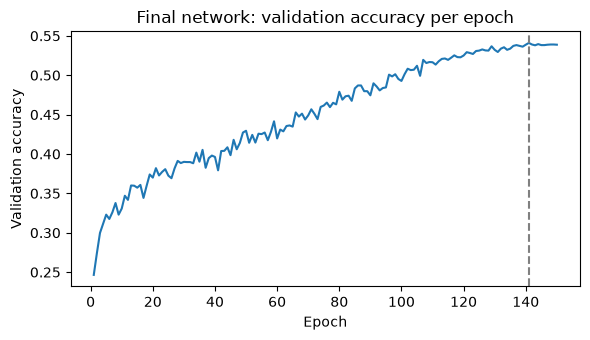

In [8]:
print("preprocessing:", best_preprocessing)
print("hidden:", best_hidden, " lr:", best_lr, " dropout:", best_dropout,
      " weight_decay:", best_weight_decay, " input_dropout:", best_input_dropout)

model = NeuralNetwork(
    epochs=150, lr=best_lr, batch_size=128, hidden=best_hidden,
    dropout=best_dropout, input_dropout=best_input_dropout,
    weight_decay=best_weight_decay, seed=42, verbose=False,
)
model.fit(Xtr, y_train, Xv, y_val)

print(evaluate_model(model, Xtr, y_train, Xv, y_val))
print("Best epoch:", model.best_epoch_)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(model.val_history) + 1), model.val_history)
plt.axvline(model.best_epoch_, linestyle="--", color="grey")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Final network: validation accuracy per epoch")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.43      0.47      0.45        80
           1       0.53      0.42      0.47        80
           2       0.69      0.78      0.73        80
           3       0.49      0.53      0.51        80
           4       0.53      0.64      0.58        80
           5       0.69      0.75      0.72        80
           6       0.41      0.36      0.39        80
           7       0.47      0.57      0.52        80
           8       0.48      0.49      0.48        80
           9       0.43      0.26      0.33        80
          10       0.49      0.35      0.41        80
          11       0.68      0.68      0.68        80
          12       0.56      0.75      0.64        80
          13       0.61      0.76      0.68        80
          14       0.56      0.60      0.58        80
          15       0.46      0.45      0.46        80
          16       0.53      0.57      0.55        80
          17       0.60    

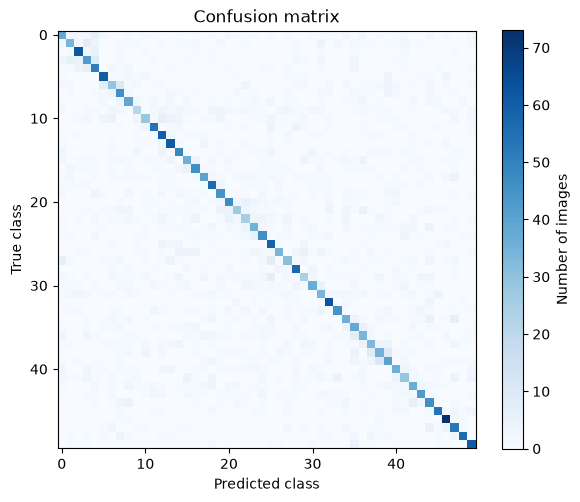

In [9]:
# Per-class results on the validation set
val_predictions = model.predict(Xv)
print_report(y_val, val_predictions)

# 50 classes: the confusion matrix is shown as a picture instead of a table
labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

## Final Model after playing around more

In [10]:
prep = make_preprocessor("sqrt_l2_global")
Xtr_final = prep.fit_transform(X_train, y_train)
Xv_final = prep.transform(X_val)

final_model = NeuralNetwork(
    epochs=150,
    lr=0.001,
    batch_size=128,
    hidden=(16384,),
    dropout=0.3,
    input_dropout=0.4,
    weight_decay=0.001,
    seed=42,
    verbose=False,
)
final_model.fit(Xtr_final, y_train, Xv_final, y_val)

print(evaluate_model(final_model, Xtr_final, y_train, Xv_final, y_val))
print("Best epoch:", final_model.best_epoch_)

{'train_accuracy': 1.0, 'val_accuracy': 0.5385, 'val_macro_f1': 0.5335626641679716}
Best epoch: 150


              precision    recall  f1-score   support

           0       0.48      0.47      0.48        80
           1       0.55      0.44      0.49        80
           2       0.66      0.76      0.71        80
           3       0.47      0.44      0.45        80
           4       0.55      0.61      0.58        80
           5       0.73      0.71      0.72        80
           6       0.36      0.35      0.35        80
           7       0.48      0.56      0.52        80
           8       0.44      0.47      0.46        80
           9       0.35      0.24      0.28        80
          10       0.41      0.35      0.38        80
          11       0.68      0.71      0.70        80
          12       0.57      0.74      0.64        80
          13       0.63      0.71      0.67        80
          14       0.66      0.62      0.64        80
          15       0.47      0.50      0.48        80
          16       0.48      0.53      0.50        80
          17       0.63    

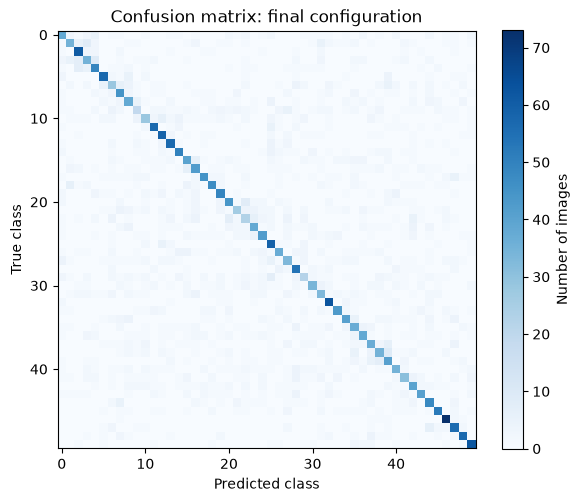

In [11]:
# Per-class results of the final configuration on the validation set
final_predictions = final_model.predict(Xv_final)
print_report(y_val, final_predictions)

labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, final_predictions, labels=labels)

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix: final configuration")
plt.tight_layout()
plt.show()